id: notebooks/06_imaging.ipynb

gridding, natural/uniform/Wiener weighting, dirty beam and dirty image

<!-- notebooks/06_imaging.ipynb -- imaging (Interferosim 0.7.0) -->
# 06 – Imaging: from visibilities to the dirty image

---
  DI Erich Schubert, 07925151
  


The visibilities of a track (notebook 04) or of the correlator (notebook 05) are samples of the Fourier transform of the sky at the measured $(u,v)$ points. Imaging puts them on a grid and transforms back. Because only a few spatial frequencies are measured, the result is not the sky but the sky convolved with the **dirty beam** – the image of a point source with this uv-coverage.

Package: `interferosim.imaging` – `Gridder`, `NaturalWeighting`, `UniformWeighting`, `WienerWeighting`, `Imager`, `Image`; plots `plot_image`, `sky_marks`. Origin: notebook A of the teaching material (case B, the sparsely sampled interferometer).

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import OH_1665, HI_21CM
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel
from interferosim.observation import Observation, UVCoverage, VisibilitySimulator
from interferosim.imaging import Gridder, Imager, NaturalWeighting, UniformWeighting, WienerWeighting
from interferosim.plotting import plot_image, plot_uv_coverage, sky_marks

CFG = Path("..") / "configs"
DATE = "2026-11-01"
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
target = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish),
                      Station.from_enu("X", site, 11_500, 0, 0, dish)], receiver=b210,
               name="project baseline 11.5 km east-west (model)")
three = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish),
                     Station.from_enu("E", site, 11_500, 0, 0, dish),
                     Station.from_enu("N", site, 0, 6_000, 0, dish)], receiver=b210,
              name="hypothetical three-station array")
masers = SkyModel.from_json(CFG / "skies" / "w3oh_masers.json")
cyga = SkyModel.from_json(CFG / "skies" / "cyg_a.json")
M1 = (masers["Maser M1"].dx_deg, masers["Maser M1"].dy_deg)       # image centre for the masers

def sidelobe_level(beam):
    """Highest beam value outside twice the main-lobe FWHM."""
    fx, fy = beam.beam_fwhm_arcsec()
    a = beam.axis_arcsec(); L, M = np.meshgrid(a, a)
    return float(beam.data[np.hypot(L, M) > np.nanmax([fx, fy])].max())

## 1. Principle

$$V(u,v) = \iint I(l,m)\,e^{-2\pi i(ul+vm)}\,dl\,dm
\quad\Longrightarrow\quad
I_D(l,m) = \sum_k w_k\,V_k\,e^{+2\pi i(u_k l+v_k m)} = (I * B_D)(l,m),$$

with the **dirty beam** $B_D(l,m) = \sum_k w_k\,e^{+2\pi i(u_k l + v_k m)}$. Steps of the `Imager`:

1. **gridding**: every visibility (and its Hermitian conjugate $V(-u,-v) = V^*(u,v)$) is added to the nearest cell of an $N\times N$ uv-grid with the cell size $\Delta u = 1/(N\,\Delta l)$; channels are gridded at their own frequency (multi-frequency synthesis);
2. **weighting** per cell (section 3);
3. inverse FFT of the weighted grid → dirty image, of the weight grid → dirty beam; both normalised so that the beam peaks at 1 – a point source then shows its flux density in Jy/beam.

## 2. The OH maser group with the project baseline

Three OH masers near W3(OH), 70, 45 and 20 Jy within 15″ (aas6sim demo field), observed at 1665 MHz for ±8 h on the 11.5 km baseline (one-minute integrations with noise). The single baseline traces one ellipse in the uv-plane; the dirty beam is a pattern of parallel fringes modulated by the ellipse – every maser appears as a copy of it. Circles: true positions.

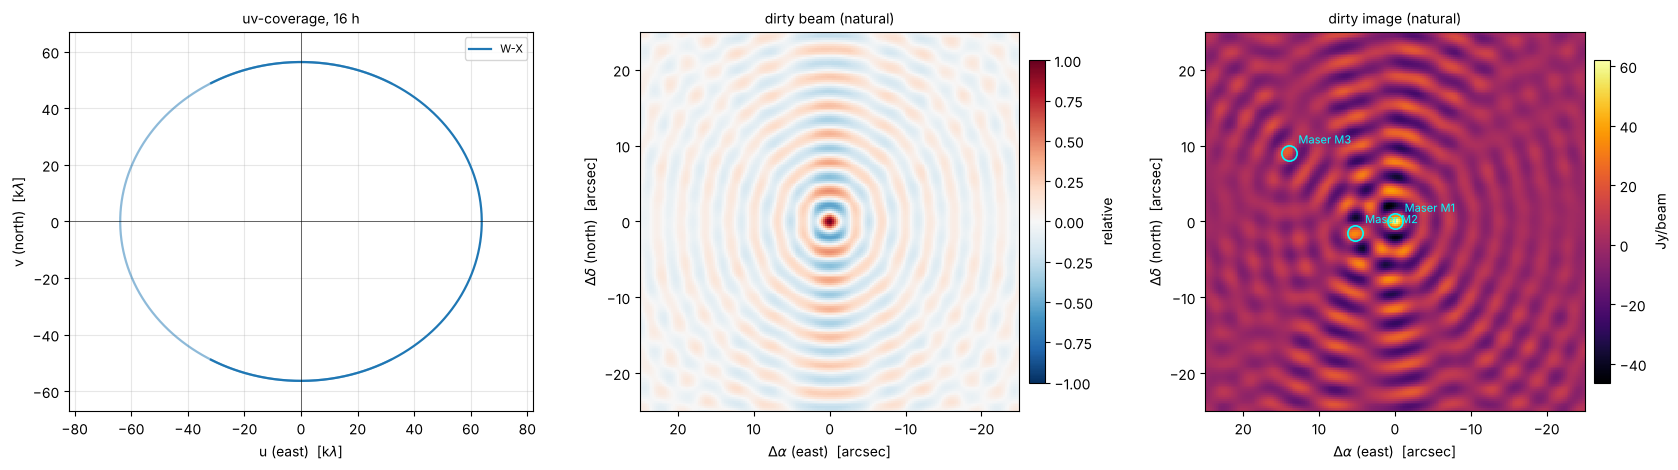

957 visibilities -> 146 uv cells; main lobe 1.78" x 1.60" (FWHM), highest sidelobe 0.46
  Maser M1: true  70.0 Jy, image at its position   62.0 Jy/beam
  Maser M2: true  45.0 Jy, image at its position   33.9 Jy/beam
  Maser M3: true  20.0 Jy, image at its position   20.4 Jy/beam


In [2]:
obs_m = Observation.from_sky(masers, target, ha_range_h=(-8, 8), t_int_s=60, freq_hz=OH_1665, date=DATE)
vd_m = VisibilitySimulator(seed=1).run(masers, obs_m)
img, beam = Imager(Gridder(256, 0.25), NaturalWeighting()).both(vd_m, center_deg=M1)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
plot_uv_coverage(UVCoverage.from_observation(obs_m), ax=axes[0], title="uv-coverage, 16 h")
plot_image(beam, ax=axes[1], zoom_arcsec=25, cmap="RdBu_r", vmin=-1, vmax=1, title="dirty beam (natural)")
plot_image(img, ax=axes[2], zoom_arcsec=25, marks=sky_marks(masers, M1), labels=True, title="dirty image (natural)")
fig.tight_layout(); plt.show()
fx, fy = beam.beam_fwhm_arcsec()
print(f"{vd_m.n_rows} visibilities -> {img.meta['n_cells']} uv cells; main lobe {fx:.2f}\" x {fy:.2f}\" (FWHM), "
      f"highest sidelobe {sidelobe_level(beam):.2f}")
for c in masers:
    l, m = (c.dx_deg - M1[0]) * 3600, (c.dy_deg - M1[1]) * 3600
    print(f"  {c.name}: true {c.flux_jy:5.1f} Jy, image at its position {img.value_at(l, m):6.1f} Jy/beam")

The values at the maser positions differ from the true flux densities: the sidelobes of each maser fall on the others. Removing this mutual contamination is the task of deconvolution (notebook 07).

## 3. Weighting

How strongly each uv cell counts decides the shape of the beam and the noise:

| weighting | weight per cell | beam | noise |
|---|---|---|---|
| natural | sum of the data weights $1/\sigma^2$ | widest main lobe | lowest |
| uniform | each occupied cell counts once | sharpest main lobe | highest |
| Wiener | $W/(W^2+K)$, $K = k\,\langle W\rangle^2$ | in between, set by $k$ | in between |

Notebook A shows why the Wiener filter, applied to a sparsely sampled interferometer, is only a re-weighting of the measured cells: outside them there is nothing to restore. The noise is measured on a map of noise alone (same observation, source switched off).

weighting            FWHM l x m  sidelobe  noise [Jy/beam]  M1 [Jy/beam]
natural            1.78" x 1.60"      0.46             0.15          62.0
Wiener k=1         1.74" x 1.63"      0.45             0.16          61.2
Wiener k=0.01      1.55" x 1.77"      0.32             0.20          59.1
uniform            1.55" x 1.77"      0.33             0.21          59.2


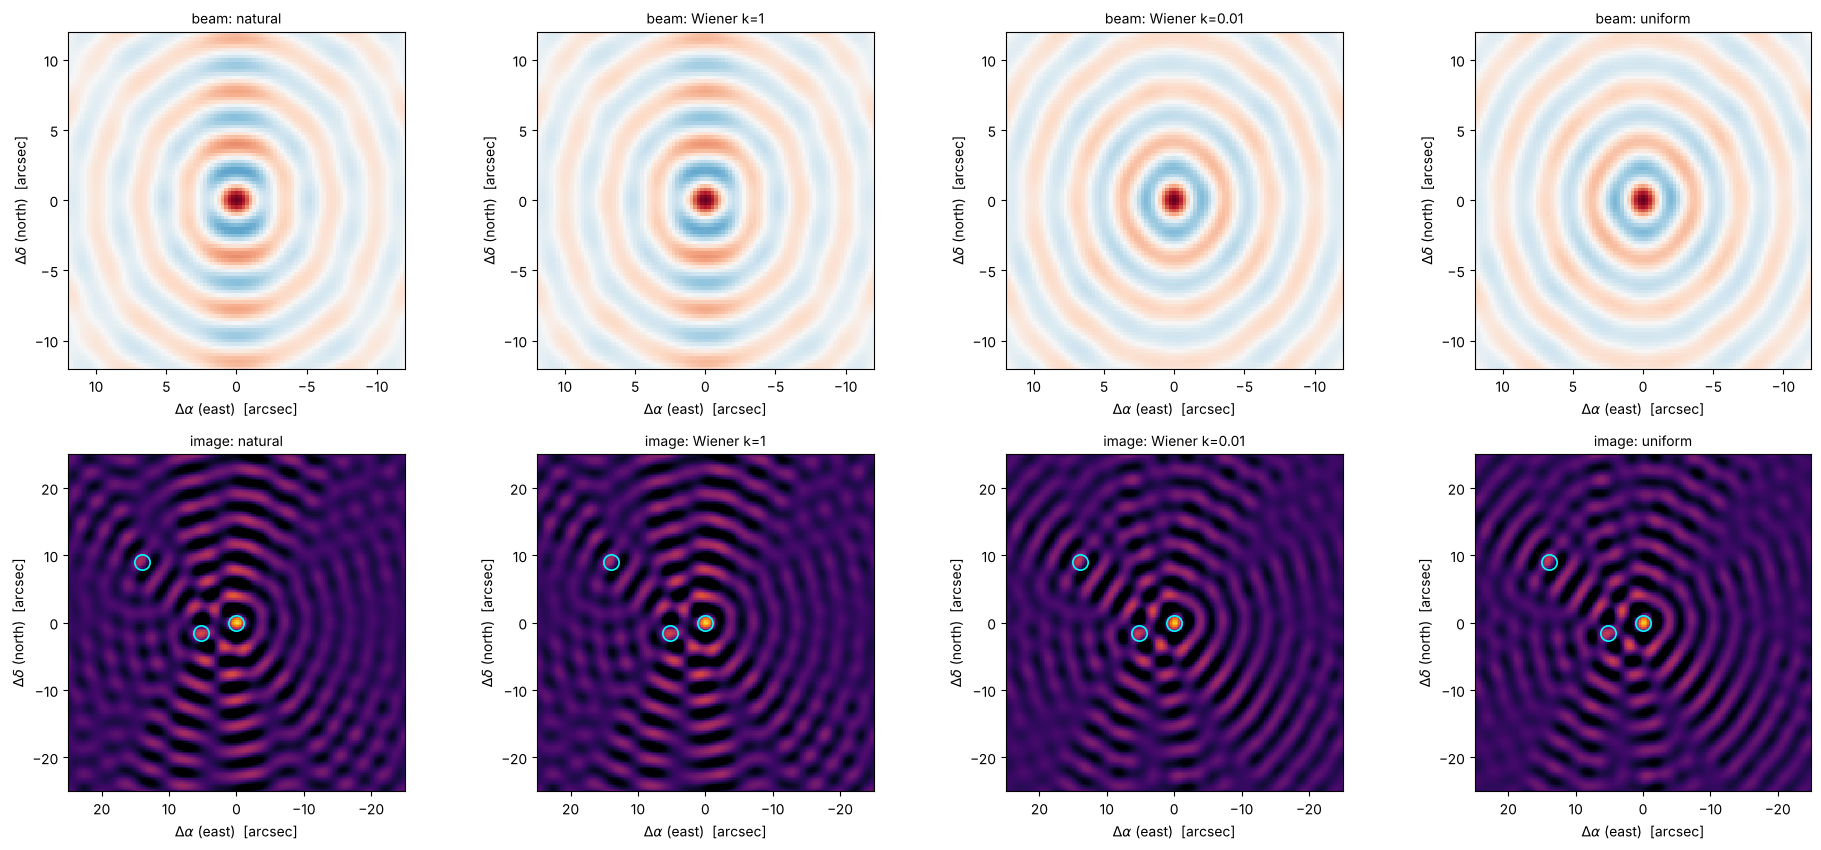

In [3]:
noise_only = VisibilitySimulator(seed=1).run(SkyModel([], center=masers.center), obs_m)
schemes = [NaturalWeighting(), WienerWeighting(1.0), WienerWeighting(0.01), UniformWeighting()]
fig, axes = plt.subplots(2, 4, figsize=(19, 8.6))
print(f"{'weighting':<16s} {'FWHM l x m':>14s} {'sidelobe':>9s} {'noise [Jy/beam]':>16s} {'M1 [Jy/beam]':>13s}")
for k, w in enumerate(schemes):
    im_w, bm_w = Imager(Gridder(256, 0.25), w).both(vd_m, center_deg=M1)
    rms = Imager(Gridder(256, 0.25), w).dirty_image(noise_only, center_deg=M1).rms()
    lab = w.name if not isinstance(w, WienerWeighting) else f"Wiener k={w.k:g}"
    plot_image(bm_w, ax=axes[0, k], zoom_arcsec=12, cmap="RdBu_r", vmin=-1, vmax=1, colorbar=False, title=f"beam: {lab}")
    plot_image(im_w, ax=axes[1, k], zoom_arcsec=25, marks=sky_marks(masers, M1), colorbar=False,
               vmin=-15, vmax=70, title=f"image: {lab}")
    fx, fy = bm_w.beam_fwhm_arcsec()
    print(f"{lab:<16s} {fx:6.2f}\" x {fy:4.2f}\" {sidelobe_level(bm_w):9.2f} {rms:16.2f} {im_w.value_at(0, 0):13.1f}")
fig.tight_layout(); plt.show()

## 4. More baselines

A third station (hypothetical, 6 km north – not a planned site) adds two baselines of other orientations: the uv-plane is filled with three ellipses, the fringes of the single-baseline beam break up, the sidelobes drop and the masers stand out much more clearly.

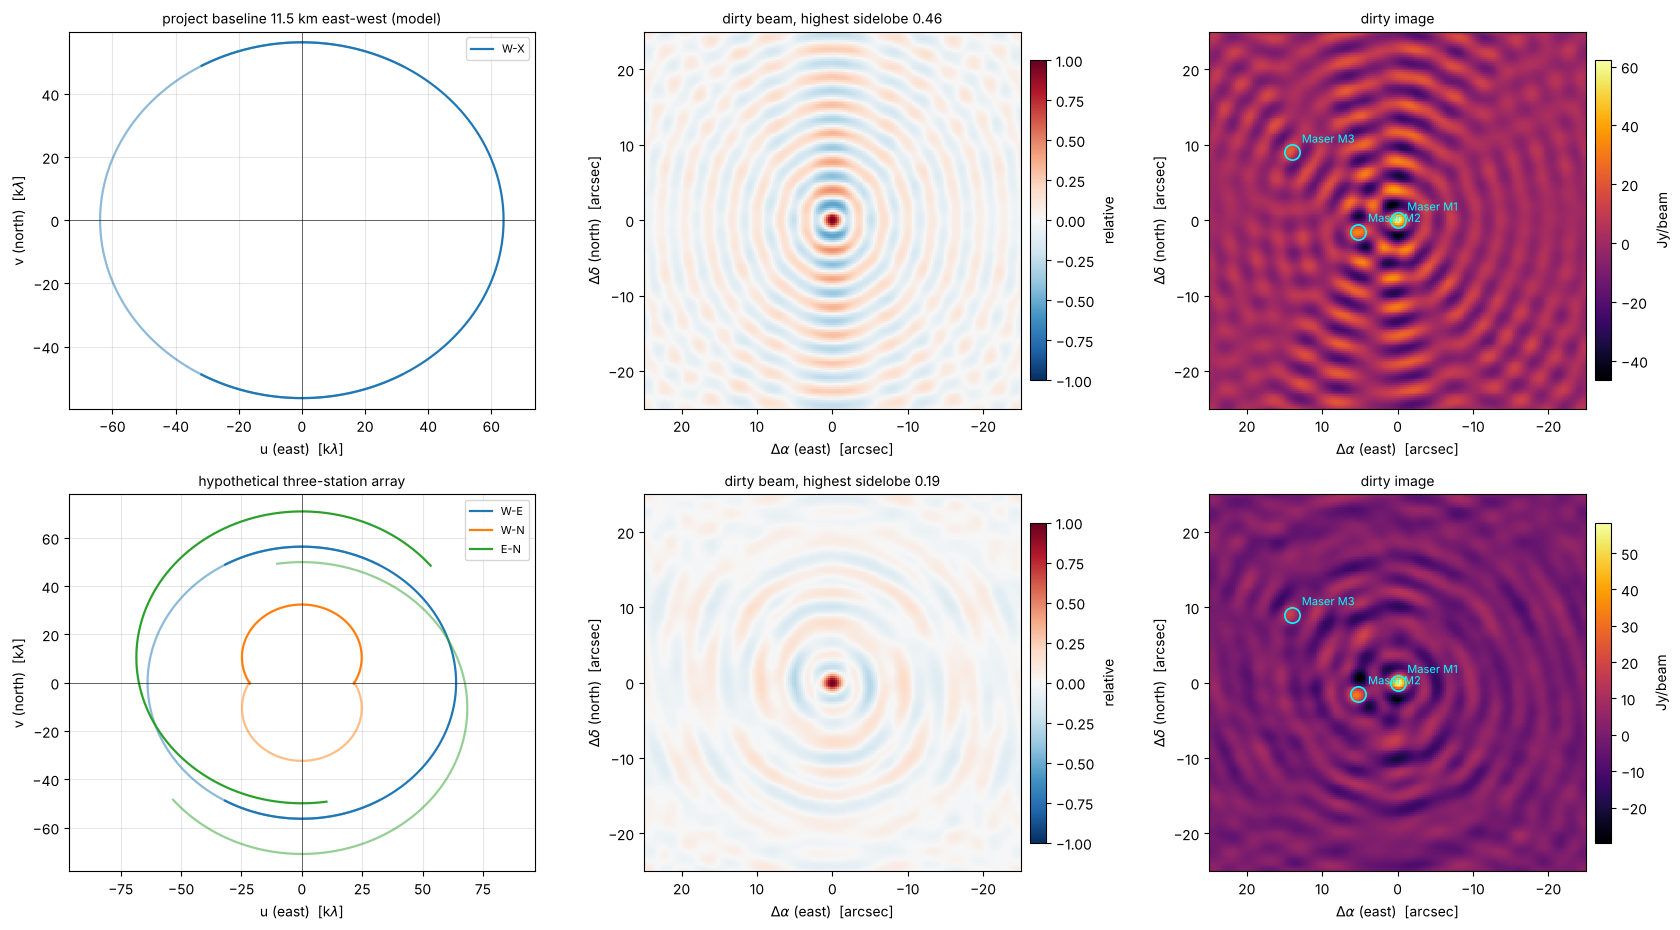

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.4))
for row, arr in enumerate((target, three)):
    o = Observation.from_sky(masers, arr, ha_range_h=(-8, 8), t_int_s=60, freq_hz=OH_1665, date=DATE)
    v = VisibilitySimulator(seed=2).run(masers, o)
    im_a, bm_a = Imager(Gridder(256, 0.25), NaturalWeighting()).both(v, center_deg=M1)
    plot_uv_coverage(UVCoverage.from_observation(o), ax=axes[row, 0], title=arr.name)
    plot_image(bm_a, ax=axes[row, 1], zoom_arcsec=25, cmap="RdBu_r", vmin=-1, vmax=1,
               title=f"dirty beam, highest sidelobe {sidelobe_level(bm_a):.2f}")
    plot_image(im_a, ax=axes[row, 2], zoom_arcsec=25, marks=sky_marks(masers, M1), labels=True, title="dirty image")
fig.tight_layout(); plt.show()

## 5. Cygnus A: what a long baseline sees of an extended source

Cygnus A at 1420 MHz, ±8 h (two-minute integrations), cell 0.5″, field 256″. The baselines of 6–13 km measure only spatial frequencies of 30–60 kλ: the compact hotspots (≈ 3″) appear, the lobes (45″ × 25″) are almost completely resolved out. Without short baselines the large-scale emission is missing; the image has no zero level – the integral of a dirty image without the zero spacing is zero, so bright features sit in negative bowls.

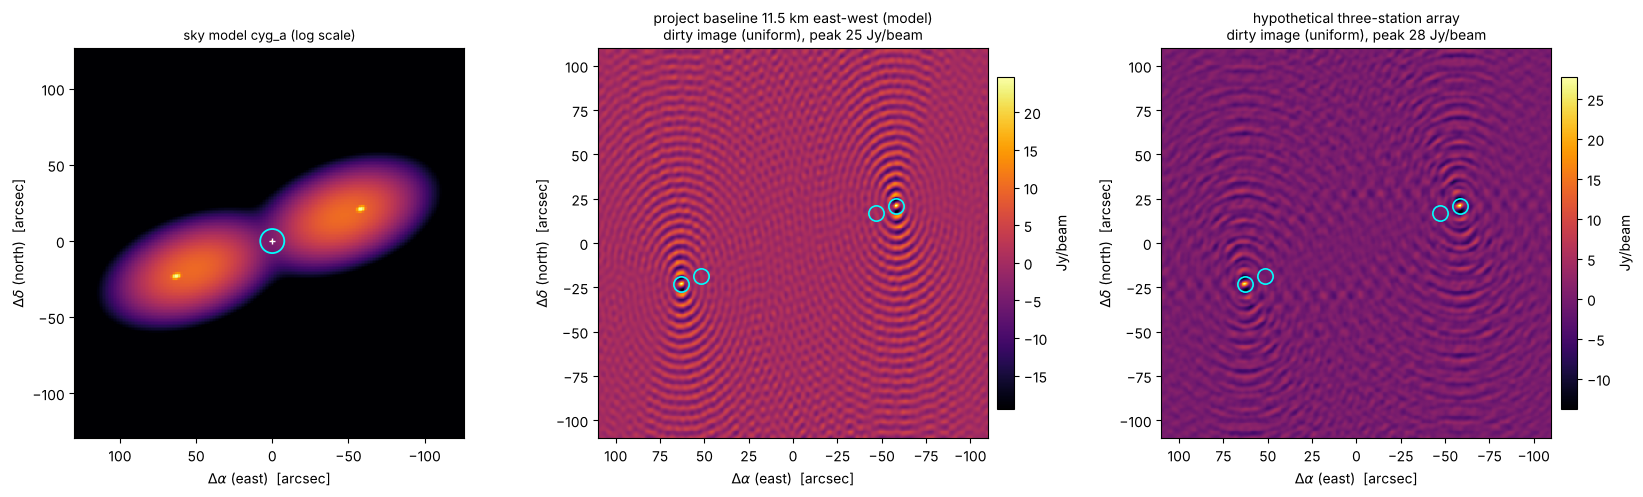

total flux density of the model: 1556.0 Jy; hotspots: ['West hotspot A 80 Jy', 'East hotspot D 75 Jy']


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
from interferosim.plotting import plot_sky_map
plot_sky_map(cyga, ax=axes[0], fov_deg=256 / 3600, npix=256, scale="log", colorbar=False, labels=False,
             title="sky model cyg_a (log scale)")
for ax, arr in zip(axes[1:], (target, three)):
    o = Observation.from_sky(cyga, arr, ha_range_h=(-8, 8), t_int_s=120, date=DATE)
    v = VisibilitySimulator(seed=3).run(cyga, o)
    im_c = Imager(Gridder(512, 0.5), UniformWeighting()).dirty_image(v)
    plot_image(im_c, ax=ax, zoom_arcsec=110, marks=sky_marks(cyga, min_flux_jy=50), colorbar=True,
               title=f"{arr.name}\ndirty image (uniform), peak {im_c.peak()[0]:.0f} Jy/beam")
fig.tight_layout(); plt.show()
print("total flux density of the model:", cyga.total_flux_jy, "Jy; hotspots:",
      [f"{c.name} {c.flux_jy:g} Jy" for c in cyga if "hotspot" in c.name])

## 6. Selector

Source, array, hour-angle range, weighting (with the Wiener parameter $k$), cell size and grid size; *Run Interact* shows uv-coverage, dirty beam and dirty image. (Needs a running kernel.)

In [6]:
import ipywidgets as widgets
from IPython.display import display

SKIES6 = {"w3oh_masers (1665 MHz)": (masers, OH_1665, M1),
          "cyg_a": (cyga, HI_21CM, (0.0, 0.0)),
          "vir_a": (SkyModel.from_json(CFG / "skies" / "vir_a.json"), HI_21CM, (0.0, 0.0))}
ARR6 = {"project baseline 11.5 km": target, "three stations (hypothetical)": three,
        "AAS6 stations 11.1 km": Array.from_toml(CFG / "sites" / "aas6_sim_stations.toml")}

def run_img(source, array_name, ha_half_h, weighting, k, cell_arcsec, npix, zoom_arcsec):
    sky, f, cen = SKIES6[source]
    arr = ARR6[array_name]
    o = Observation.from_sky(sky, arr, ha_range_h=(-ha_half_h, ha_half_h), t_int_s=120, freq_hz=f, date=DATE)
    if not o.visible().any():
        print("source below the elevation limit"); return
    v = VisibilitySimulator(seed=4).run(sky, o)
    w = {"natural": NaturalWeighting(), "uniform": UniformWeighting(), "Wiener": WienerWeighting(k)}[weighting]
    im_s, bm_s = Imager(Gridder(npix, cell_arcsec), w).both(v, center_deg=cen)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    plot_uv_coverage(UVCoverage.from_observation(o), ax=axes[0])
    plot_image(bm_s, ax=axes[1], zoom_arcsec=zoom_arcsec, cmap="RdBu_r", vmin=-1, vmax=1, title="dirty beam")
    plot_image(im_s, ax=axes[2], zoom_arcsec=zoom_arcsec, marks=sky_marks(sky, cen, min_flux_jy=10), title="dirty image")
    fig.tight_layout(); plt.show()
    fx, fy = bm_s.beam_fwhm_arcsec()
    print(f"field {npix * cell_arcsec:.0f}\", main lobe {fx:.2f}\" x {fy:.2f}\", highest sidelobe {sidelobe_level(bm_s):.2f}, "
          f"peak {im_s.peak()[0]:.1f} Jy/beam, {im_s.meta['dropped']} visibilities outside the grid")

display(widgets.interactive(
    run_img, {"manual": True},
    source=widgets.Dropdown(options=list(SKIES6), description="source"),
    array_name=widgets.Dropdown(options=list(ARR6), description="array"),
    ha_half_h=widgets.FloatSlider(value=8, min=0.5, max=12, step=0.5, description="±HA [h]"),
    weighting=widgets.ToggleButtons(options=["natural", "uniform", "Wiener"], description="weighting"),
    k=widgets.FloatLogSlider(value=1, base=10, min=-3, max=2, description="Wiener k"),
    cell_arcsec=widgets.Dropdown(options=[0.1, 0.25, 0.5, 1.0], value=0.25, description="cell [\"]"),
    npix=widgets.Dropdown(options=[128, 256, 512, 1024], value=256, description="N grid"),
    zoom_arcsec=widgets.FloatSlider(value=25, min=5, max=250, step=5, description="zoom [\"]"),
))

interactive(children=(Dropdown(description='source', options=('w3oh_masers (1665 MHz)', 'cyg_a', 'vir_a'), val…